<a href="https://colab.research.google.com/github/agugun/axscnt-notebook/blob/main/partial_differential_eq/Laplace_Poisson_Equation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laplace and Poisson Equations: steady state

**PDE type: elliptic**

$$\nabla^2 u = 0 \quad \text{(Laplace)}, \qquad \nabla^2 u = f \quad \text{(Poisson, with a source } f\text{)}$$

**Where it comes from:** take the diffusion equation $\partial_t u = D\nabla^2 u$ and wait until nothing changes any more. Then $\partial_t u = 0$ and what is left is $\nabla^2 u = 0$. So the Laplace equation describes **equilibrium**: the end state of diffusion. With sources or sinks inside (a heater, a well) it becomes the Poisson equation.

**What it means:** $\nabla^2 u = 0$ says every point equals the **average of its neighbours** (the Laplacian from the differential notebook). Two consequences follow:
- **Mean-value property:** the value at a point equals the average over any circle around it.
- **Maximum principle:** there are no hills or valleys inside, so the largest and smallest values sit on the boundary.

**Classification of second-order PDEs.** For $A\,u_{xx} + 2B\,u_{xy} + C\,u_{yy} + \dots = 0$ (with $t$ counted as one of the variables), the sign of $B^2 - AC$ sets the type:

| Type | $B^2 - AC$ | Prototype | Describes | Needs | Solved by | Notebook |
|---|---|---|---|---|---|---|
| **elliptic** | $< 0$ | $\nabla^2 u = f$ | equilibrium, steady state | boundary values only | one linear system for the whole domain | this one |
| **parabolic** | $= 0$ | $u_t = D\nabla^2 u$ | smoothing toward equilibrium | initial + boundary values | marching in time | `Diffusion_Equation.ipynb` |
| **hyperbolic** | $> 0$ | $u_{tt} = c^2\nabla^2 u$ | propagation at finite speed | $u$ and $u_t$ initially + boundary | marching in time (CFL) | `Wave_Equation.ipynb` |

There is no time here, so there is no initial condition and no stability limit. Instead, **every point depends on the whole boundary at once**, and we must solve for all points together.

| Part | Problem | Methods |
|---|---|---|
| 1 | steady temperature in a plate (Laplace) | sparse direct solve, Fourier series, diffusion run to steady state, mean-value and maximum principle checks |
| 2 | iterative solvers | Jacobi, Gauss–Seidel, SOR: why Jacobi is just slow diffusion |
| 3 | steady pressure around wells (Laplace and Poisson) | transient radial flow settling to the Thiem solution; a producer–injector pair in 2D |

## Part 1: Steady temperature in a plate (Laplace)

A unit square plate whose top edge is held at $100^\circ$C and whose other three edges are held at $0^\circ$C. What is the temperature inside once it has stopped changing?

$$\nabla^2 u = u_{xx} + u_{yy} = 0, \qquad u(x, 1) = 100, \quad u(x, 0) = u(0, y) = u(1, y) = 0$$

**Numerical method (5-point stencil):** at every interior grid point,

$$\frac{u_{i+1,j} + u_{i-1,j} + u_{i,j+1} + u_{i,j-1} - 4u_{i,j}}{h^2} = 0 \quad\Longleftrightarrow\quad u_{i,j} = \text{average of its 4 neighbours}$$

That is one equation per interior point, all coupled together: a sparse linear system $A\mathbf u = \mathbf b$, where $\mathbf b$ holds the known boundary values.

**Exact solution (separation of variables):**

$$u(x, y) = \sum_{n\ \text{odd}} \frac{400}{n\pi}\, \sin(n\pi x)\, \frac{\sinh(n\pi y)}{\sinh(n\pi)}$$

**Link to diffusion:** we also start the plate at $0^\circ$C everywhere, run the heat equation, and watch it settle onto the Laplace solution.

In [1]:
# LAPLACE IN A PLATE: sparse direct solve, Fourier series, diffusion to steady state, checks
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import spsolve
from scipy.interpolate import RegularGridInterpolator

# 1. Grid and boundary values (array index [j, i] = [y, x])
N = 81
x = np.linspace(0, 1, N)
y = np.linspace(0, 1, N)
h = x[1] - x[0]
X, Y = np.meshgrid(x, y)
u_top = 100.0
ub = np.zeros((N, N))
ub[-1, :] = u_top                      # top edge hot, the other edges at 0


def laplace_matrix(n, h):
    # 5-point Laplacian on an n x n block of interior unknowns (row-major, x fastest)
    T = sp.diags([1.0, -2.0, 1.0], [-1, 0, 1], shape=(n, n))
    I = sp.identity(n)
    return ((sp.kron(I, T) + sp.kron(T, I)) / h**2).tocsr()


def solve_poisson(ub, f, h):
    # Solve lap(u) = f in the interior, u = ub on the boundary
    n = ub.shape[0] - 2
    B = (ub[2:, 1:-1] + ub[:-2, 1:-1] + ub[1:-1, 2:] + ub[1:-1, :-2]) / h**2   # known boundary neighbours
    rhs = (f[1:-1, 1:-1] - B).ravel()
    u = ub.copy()
    u[1:-1, 1:-1] = spsolve(laplace_matrix(n, h), rhs).reshape(n, n)
    return u


U = solve_poisson(ub, np.zeros((N, N)), h)
print(f"sparse direct solve: {(N - 2)**2} unknowns, "
      f"{laplace_matrix(N - 2, h).nnz} non-zeros (at most 5 per row)")

# 2. Exact Fourier series (sinh ratio written with exponentials to avoid overflow)
n_odd = np.arange(1, 400, 2)[:, None, None]
ratio = np.exp(n_odd * np.pi * (Y - 1)) * (1 - np.exp(-2 * n_odd * np.pi * Y)) / (1 - np.exp(-2 * n_odd * np.pi))
U_exact = np.sum(400 / (n_odd * np.pi) * np.sin(n_odd * np.pi * X) * ratio, axis=0)
U_exact[-1, :] = u_top
inner = (slice(1, -1), slice(1, -1))
away = (X > 0.1) & (X < 0.9) & (Y < 0.9)          # away from the two hot corners (jumps 0 -> 100)
print(f"max |numerical - Fourier|: whole interior {np.abs(U - U_exact)[inner].max():.3f} C, "
      f"away from the hot corners {np.abs(U - U_exact)[away].max():.4f} C")

# 3. Mean-value property: centre value = average over circles around it
interp = RegularGridInterpolator((y, x), U)
xc, yc = 0.5, 0.45
theta = np.linspace(0, 2 * np.pi, 720, endpoint=False)
radii = np.array([0.1, 0.2, 0.3, 0.4])
circle_avg = np.array([interp(np.c_[yc + R * np.sin(theta), xc + R * np.cos(theta)]).mean() for R in radii])
u_centre = interp([[yc, xc]])[0]
print(f"\nmean-value property at ({xc}, {yc}): centre u = {u_centre:.3f} C")
for R, a in zip(radii, circle_avg):
    print(f"  average over circle r = {R:.1f}: {a:.3f} C")

# 4. Maximum principle
print(f"\nmaximum principle: interior range [{U[inner].min():.3f}, {U[inner].max():.3f}] C "
      f"lies strictly inside the boundary range [0, {u_top:.0f}] C")

# 5. Diffusion run to steady state: u_t = lap(u), plate initially at 0 C
r_ftcs = 0.24
dt = r_ftcs * h**2
t_snap = [0.002, 0.01, 0.03, 0.1, 0.6]
u_t = ub.copy()
mid = N // 2
profiles, t_now, k = [], 0.0, 0
for ts in t_snap:
    while t_now < ts - 1e-12:
        u_t[1:-1, 1:-1] += r_ftcs * (u_t[2:, 1:-1] + u_t[:-2, 1:-1] + u_t[1:-1, 2:] + u_t[1:-1, :-2] - 4 * u_t[1:-1, 1:-1])
        t_now += dt
        k += 1
    profiles.append(u_t[:, mid].copy())
print(f"\ndiffusion from u = 0: after t = {t_now:.2f} ({k} steps) max |u(t) - Laplace solution| = {np.abs(u_t - U).max():.2e} C")

sparse direct solve: 6241 unknowns, 30889 non-zeros (at most 5 per row)
max |numerical - Fourier|: whole interior 0.718 C, away from the hot corners 0.0147 C

mean-value property at (0.5, 0.45): centre u = 21.089 C
  average over circle r = 0.1: 21.089 C
  average over circle r = 0.2: 21.089 C
  average over circle r = 0.3: 21.089 C
  average over circle r = 0.4: 21.088 C

maximum principle: interior range [0.017, 97.481] C lies strictly inside the boundary range [0, 100] C



diffusion from u = 0: after t = 0.60 (16000 steps) max |u(t) - Laplace solution| = 2.90e-04 C


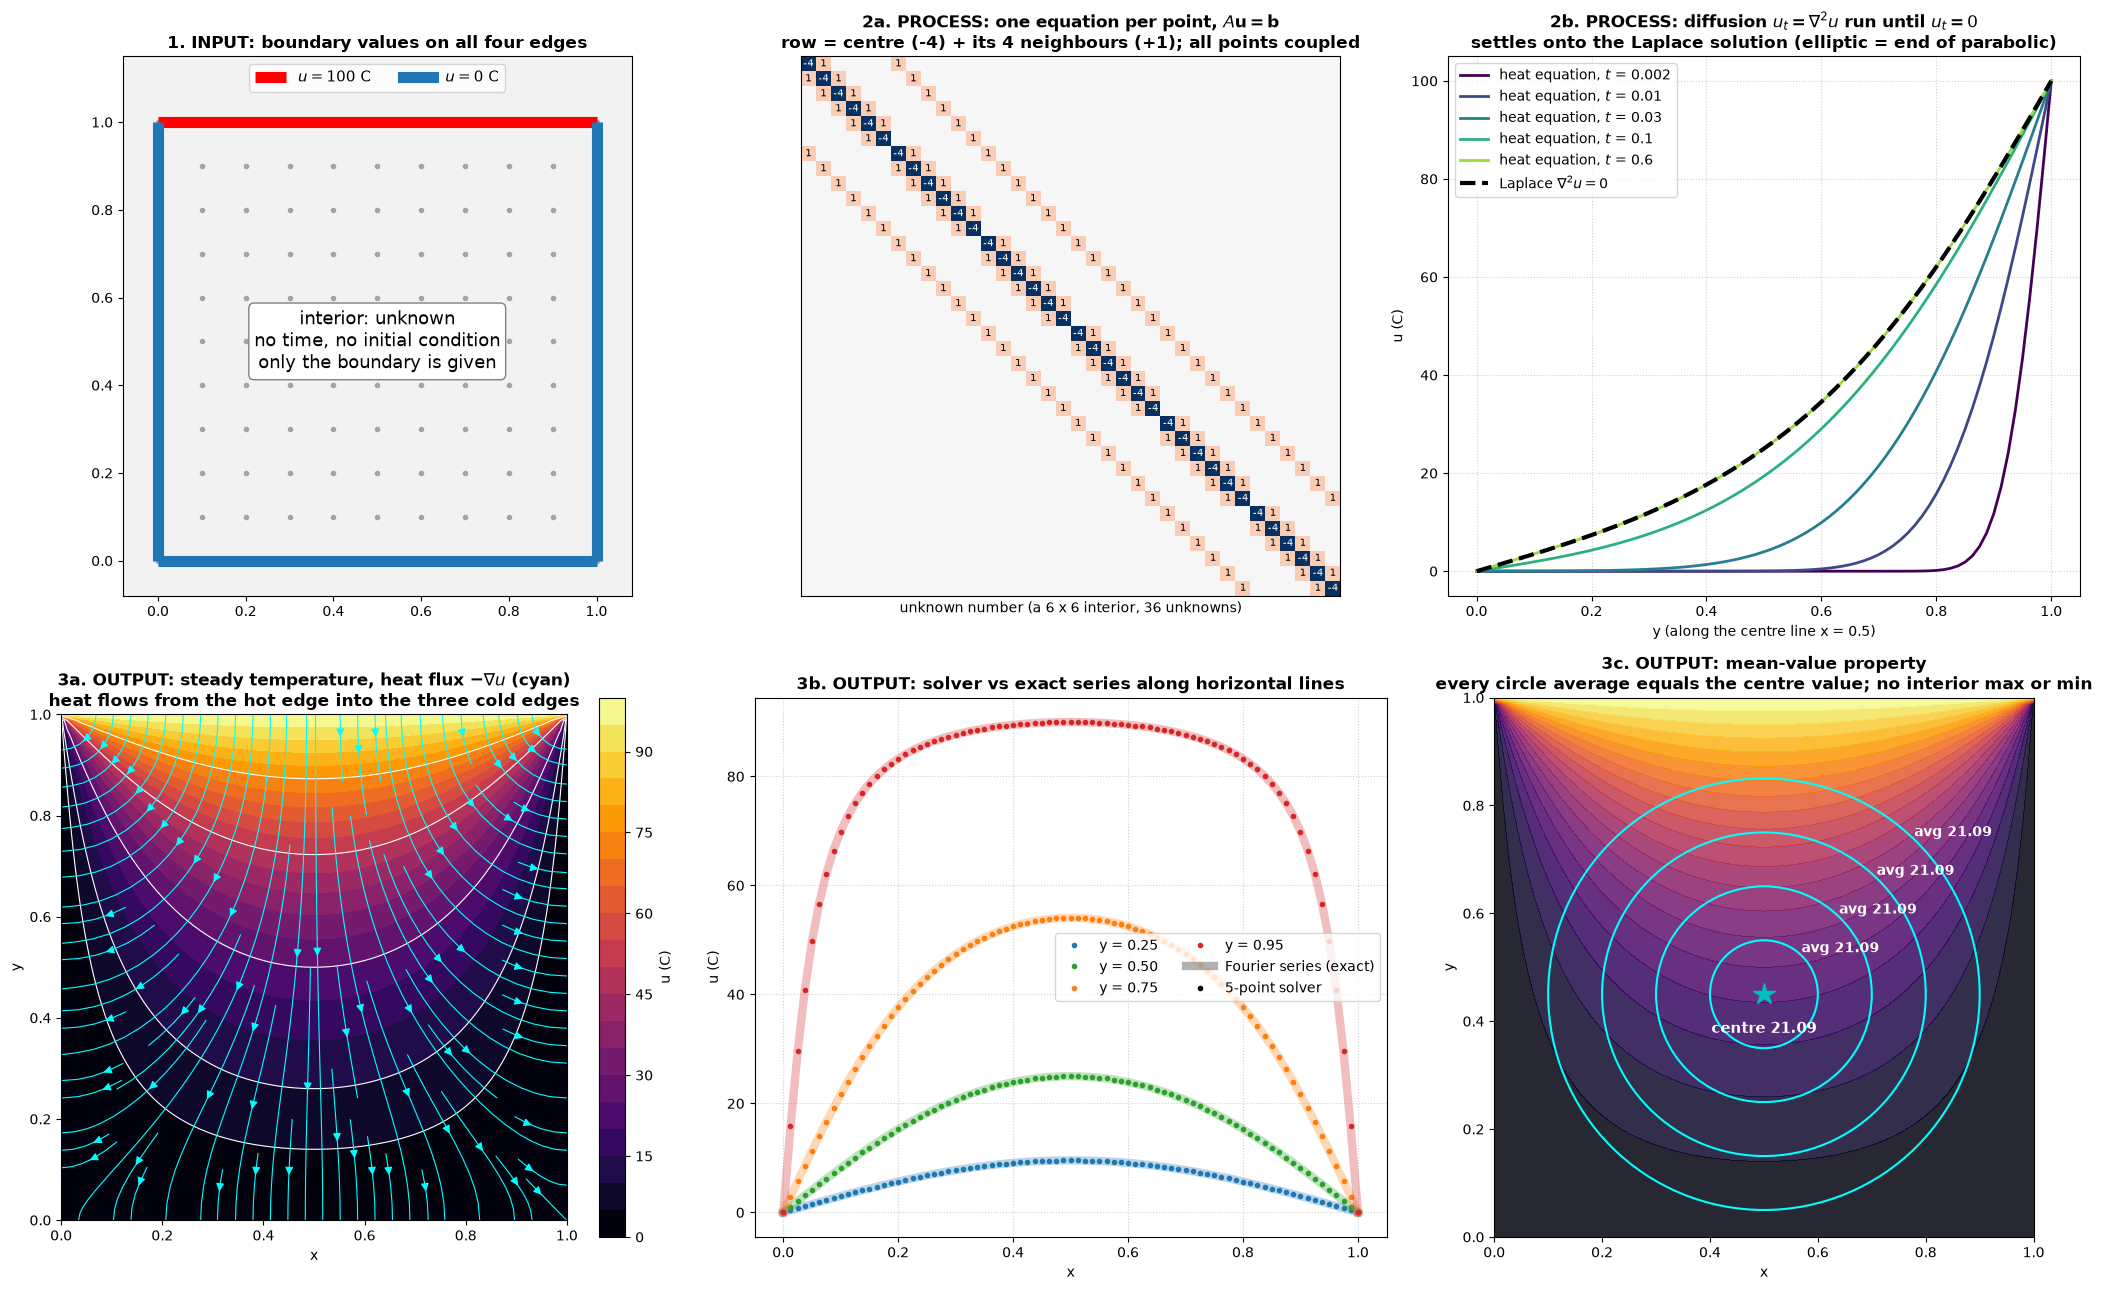

In [2]:
# LAPLACE IN A PLATE: INPUT -> PROCESS -> OUTPUT
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

fig, axes = plt.subplots(2, 3, figsize=(21, 13))

# Panel 1: INPUT (boundary values only)
ax = axes[0, 0]
ax.set_facecolor('#f2f2f2')
xs = x[::8]
ax.plot(*np.meshgrid(xs, xs), 'o', color='gray', ms=3, alpha=0.6)
ax.plot([0, 1], [1, 1], color='red', lw=8, solid_capstyle='butt', label='$u = 100$ C')
for seg in ([[0, 1], [0, 0]], [[0, 0], [0, 1]], [[1, 1], [0, 1]]):
    ax.plot(*seg, color='tab:blue', lw=8, solid_capstyle='butt')
ax.plot([], [], color='tab:blue', lw=8, label='$u = 0$ C')
ax.text(0.5, 0.5, 'interior: unknown\nno time, no initial condition\nonly the boundary is given',
        ha='center', va='center', fontsize=13, bbox=dict(boxstyle='round', fc='white', ec='gray'))
ax.set_xlim(-0.08, 1.08)
ax.set_ylim(-0.08, 1.15)
ax.set_aspect('equal')
ax.legend(loc='upper center', ncol=2, fontsize=11, bbox_to_anchor=(0.5, 1.0))
ax.set_title('1. INPUT: boundary values on all four edges', fontsize=12, fontweight='bold')

# Panel 2a: PROCESS (the linear system)
ax = axes[0, 1]
n_small = 6
A_small = laplace_matrix(n_small, 1.0).toarray()
im = ax.imshow(A_small, cmap='RdBu_r', vmin=-4, vmax=4)
ax.set_xticks([])
ax.set_yticks([])
for (r_, c_), val in np.ndenumerate(A_small):
    if val != 0:
        ax.text(c_, r_, f'{val:.0f}', ha='center', va='center', fontsize=7, color='white' if val < 0 else 'black')
ax.set_xlabel(f'unknown number (a {n_small} x {n_small} interior, {n_small**2} unknowns)')
ax.set_title(r'2a. PROCESS: one equation per point, $A\mathbf{u} = \mathbf{b}$' + '\n'
             + 'row = centre (-4) + its 4 neighbours (+1); all points coupled', fontsize=12, fontweight='bold')

# Panel 2b: PROCESS (diffusion settling to the Laplace solution)
ax = axes[0, 2]
colors = plt.cm.viridis(np.linspace(0, 0.85, len(t_snap)))
for prof, ts, col in zip(profiles, t_snap, colors):
    ax.plot(y, prof, color=col, lw=2, label=f'heat equation, $t$ = {ts}')
ax.plot(y, U[:, mid], 'k--', lw=3, label=r'Laplace $\nabla^2 u = 0$')
ax.set_xlabel('y (along the centre line x = 0.5)')
ax.set_ylabel('u (C)')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=10)
ax.set_title(r'2b. PROCESS: diffusion $u_t = \nabla^2 u$ run until $u_t = 0$' + '\n'
             + 'settles onto the Laplace solution (elliptic = end of parabolic)', fontsize=12, fontweight='bold')

# Panel 3a: OUTPUT (temperature map and heat flux)
ax = axes[1, 0]
cf = ax.contourf(X, Y, U, levels=np.linspace(0, 100, 21), cmap='inferno')
ax.contour(X, Y, U, levels=[5, 10, 25, 50, 75], colors='white', linewidths=0.8)
gy, gx = np.gradient(U, h)
ax.streamplot(x, y, -gx, -gy, color='cyan', density=1.0, linewidth=0.8, arrowsize=1.2)
fig.colorbar(cf, ax=ax, label='u (C)')
ax.set_aspect('equal')
ax.set_title('3a. OUTPUT: steady temperature, heat flux $-\\nabla u$ (cyan)\n'
             'heat flows from the hot edge into the three cold edges', fontsize=12, fontweight='bold')

# Panel 3b: OUTPUT (numerical vs Fourier)
ax = axes[1, 1]
for yy, col in zip([0.25, 0.5, 0.75, 0.95], ['tab:blue', 'tab:green', 'tab:orange', 'tab:red']):
    j = np.argmin(np.abs(y - yy))
    ax.plot(x, U_exact[j], '-', color=col, lw=6, alpha=0.3)
    ax.plot(x, U[j], 'o', color=col, ms=3, label=f'y = {y[j]:.2f}')
ax.plot([], [], 'k-', lw=6, alpha=0.3, label='Fourier series (exact)')
ax.plot([], [], 'ko', ms=3, label='5-point solver')
ax.set_xlabel('x')
ax.set_ylabel('u (C)')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=10, ncol=2)
ax.set_title('3b. OUTPUT: solver vs exact series along horizontal lines', fontsize=12, fontweight='bold')

# Panel 3c: OUTPUT (mean-value property and maximum principle)
ax = axes[1, 2]
cf = ax.contourf(X, Y, U, levels=np.linspace(0, 100, 21), cmap='inferno', alpha=0.85)
for R, a in zip(radii, circle_avg):
    ax.add_patch(Circle((xc, yc), R, fill=False, ec='cyan', lw=1.5))
    ax.text(xc + R * np.cos(0.8), yc + R * np.sin(0.8), f'avg {a:.2f}', color='white', fontsize=10,
            fontweight='bold', ha='left', va='bottom')
ax.plot(xc, yc, 'c*', ms=16)
ax.text(xc, yc - 0.05, f'centre {u_centre:.2f}', color='white', ha='center', va='top', fontsize=11, fontweight='bold')
ax.set_aspect('equal')
ax.set_title('3c. OUTPUT: mean-value property\n'
             'every circle average equals the centre value; no interior max or min', fontsize=12, fontweight='bold')
for ax in (axes[1, 0], axes[1, 2]):
    ax.set_xlabel('x')
    ax.set_ylabel('y')

plt.tight_layout()
plt.show()

## Part 2: Iterative solvers

The direct solve in Part 1 is fine for thousands of unknowns, but large 2D and 3D problems are usually solved by **iteration**: start from a guess and repeatedly enforce "each point = average of its neighbours".

| Method | Update | Convergence factor per sweep ($h = 1/(N-1)$) |
|---|---|---|
| Jacobi | new value = average of the **old** neighbours | $\rho_J = \cos(\pi h) \approx 1 - \tfrac{\pi^2 h^2}{2}$ |
| Gauss–Seidel | use **new** neighbour values as soon as they exist | $\rho_{GS} = \rho_J^2$ (twice as fast) |
| SOR | Gauss–Seidel step, then overshoot by $\omega$: $u \leftarrow u + \omega(\bar u - u)$ | $\rho = \omega_{opt} - 1$ with $\omega_{opt} = \dfrac{2}{1 + \sin(\pi h)}$ |

**Jacobi is diffusion:** the Jacobi update $u \leftarrow u + \tfrac14(\text{sum of neighbours} - 4u)$ is exactly the explicit heat equation step with $r = \tfrac14$, the 2D stability limit. So Jacobi iterations look like heat soaking into the plate, and they are as slow as diffusion: the number of sweeps grows like $N^2$. SOR cuts this to about $N$.

Gauss–Seidel and SOR are written here in **red–black** order (like a chessboard): update all red points from their black neighbours, then all black points, which is the same as Gauss–Seidel with that ordering and can be vectorised.

In [3]:
# ITERATIVE SOLVERS: Jacobi, Gauss-Seidel, SOR on the same plate
import numpy as np

N2 = 41
x2 = np.linspace(0, 1, N2)
h2 = x2[1] - x2[0]
ub2 = np.zeros((N2, N2))
ub2[-1, :] = u_top
U_direct = solve_poisson(ub2, np.zeros((N2, N2)), h2)

J2, I2 = np.mgrid[0:N2, 0:N2]
interior = np.zeros((N2, N2), bool)
interior[1:-1, 1:-1] = True
red = interior & ((I2 + J2) % 2 == 0)
black = interior & ((I2 + J2) % 2 == 1)


def nbr_avg(u):
    a = np.zeros_like(u)
    a[1:-1, 1:-1] = 0.25 * (u[2:, 1:-1] + u[:-2, 1:-1] + u[1:-1, 2:] + u[1:-1, :-2])
    return a


def iterate(method, omega=1.0, tol=1e-6, max_iter=50000, keep=()):
    u = ub2.copy()
    res, snaps = [], {}
    for it in range(1, max_iter + 1):
        if method == 'jacobi':
            u[interior] = nbr_avg(u)[interior]
        else:
            for colour in (red, black):
                u[colour] += omega * (nbr_avg(u)[colour] - u[colour])
        r = np.abs(nbr_avg(u) - u)[interior].max()   # how far from "u = average of neighbours"
        res.append(r)
        if it in keep:
            snaps[it] = u.copy()
        if r < tol:
            break
    for kk in keep:
        snaps.setdefault(kk, u.copy())          # already converged before sweep kk
    return u, np.array(res), snaps


rho_J = np.cos(np.pi * h2)
omega_opt = 2 / (1 + np.sin(np.pi * h2))
keep = (10, 100, 1000)
runs = {}
runs['Jacobi'] = iterate('jacobi', keep=keep)
runs['Gauss-Seidel'] = iterate('gs', omega=1.0)
runs[f'SOR (omega = {omega_opt:.3f})'] = iterate('gs', omega=omega_opt, keep=keep)
rates = {'Jacobi': rho_J, 'Gauss-Seidel': rho_J**2, f'SOR (omega = {omega_opt:.3f})': omega_opt - 1}

print(f"{(N2 - 2)**2} unknowns, stop when max |avg of neighbours - u| < 1e-6 C")
for name, (u_it, res, _) in runs.items():
    print(f"  {name:22s}: {len(res):5d} sweeps, max |u - direct solve| = {np.abs(u_it - U_direct).max():.1e} C, "
          f"theory factor per sweep {rates[name]:.5f}")
print("note: the error is larger than the residual by about 1 / (1 - factor), so slow methods need a tight tolerance")

1521 unknowns, stop when max |avg of neighbours - u| < 1e-6 C
  Jacobi                :  3801 sweeps, max |u - direct solve| = 3.2e-04 C, theory factor per sweep 0.99692
  Gauss-Seidel          :  2013 sweeps, max |u - direct solve| = 1.6e-04 C, theory factor per sweep 0.99384
  SOR (omega = 1.854)   :   116 sweeps, max |u - direct solve| = 1.0e-05 C, theory factor per sweep 0.85450
note: the error is larger than the residual by about 1 / (1 - factor), so slow methods need a tight tolerance


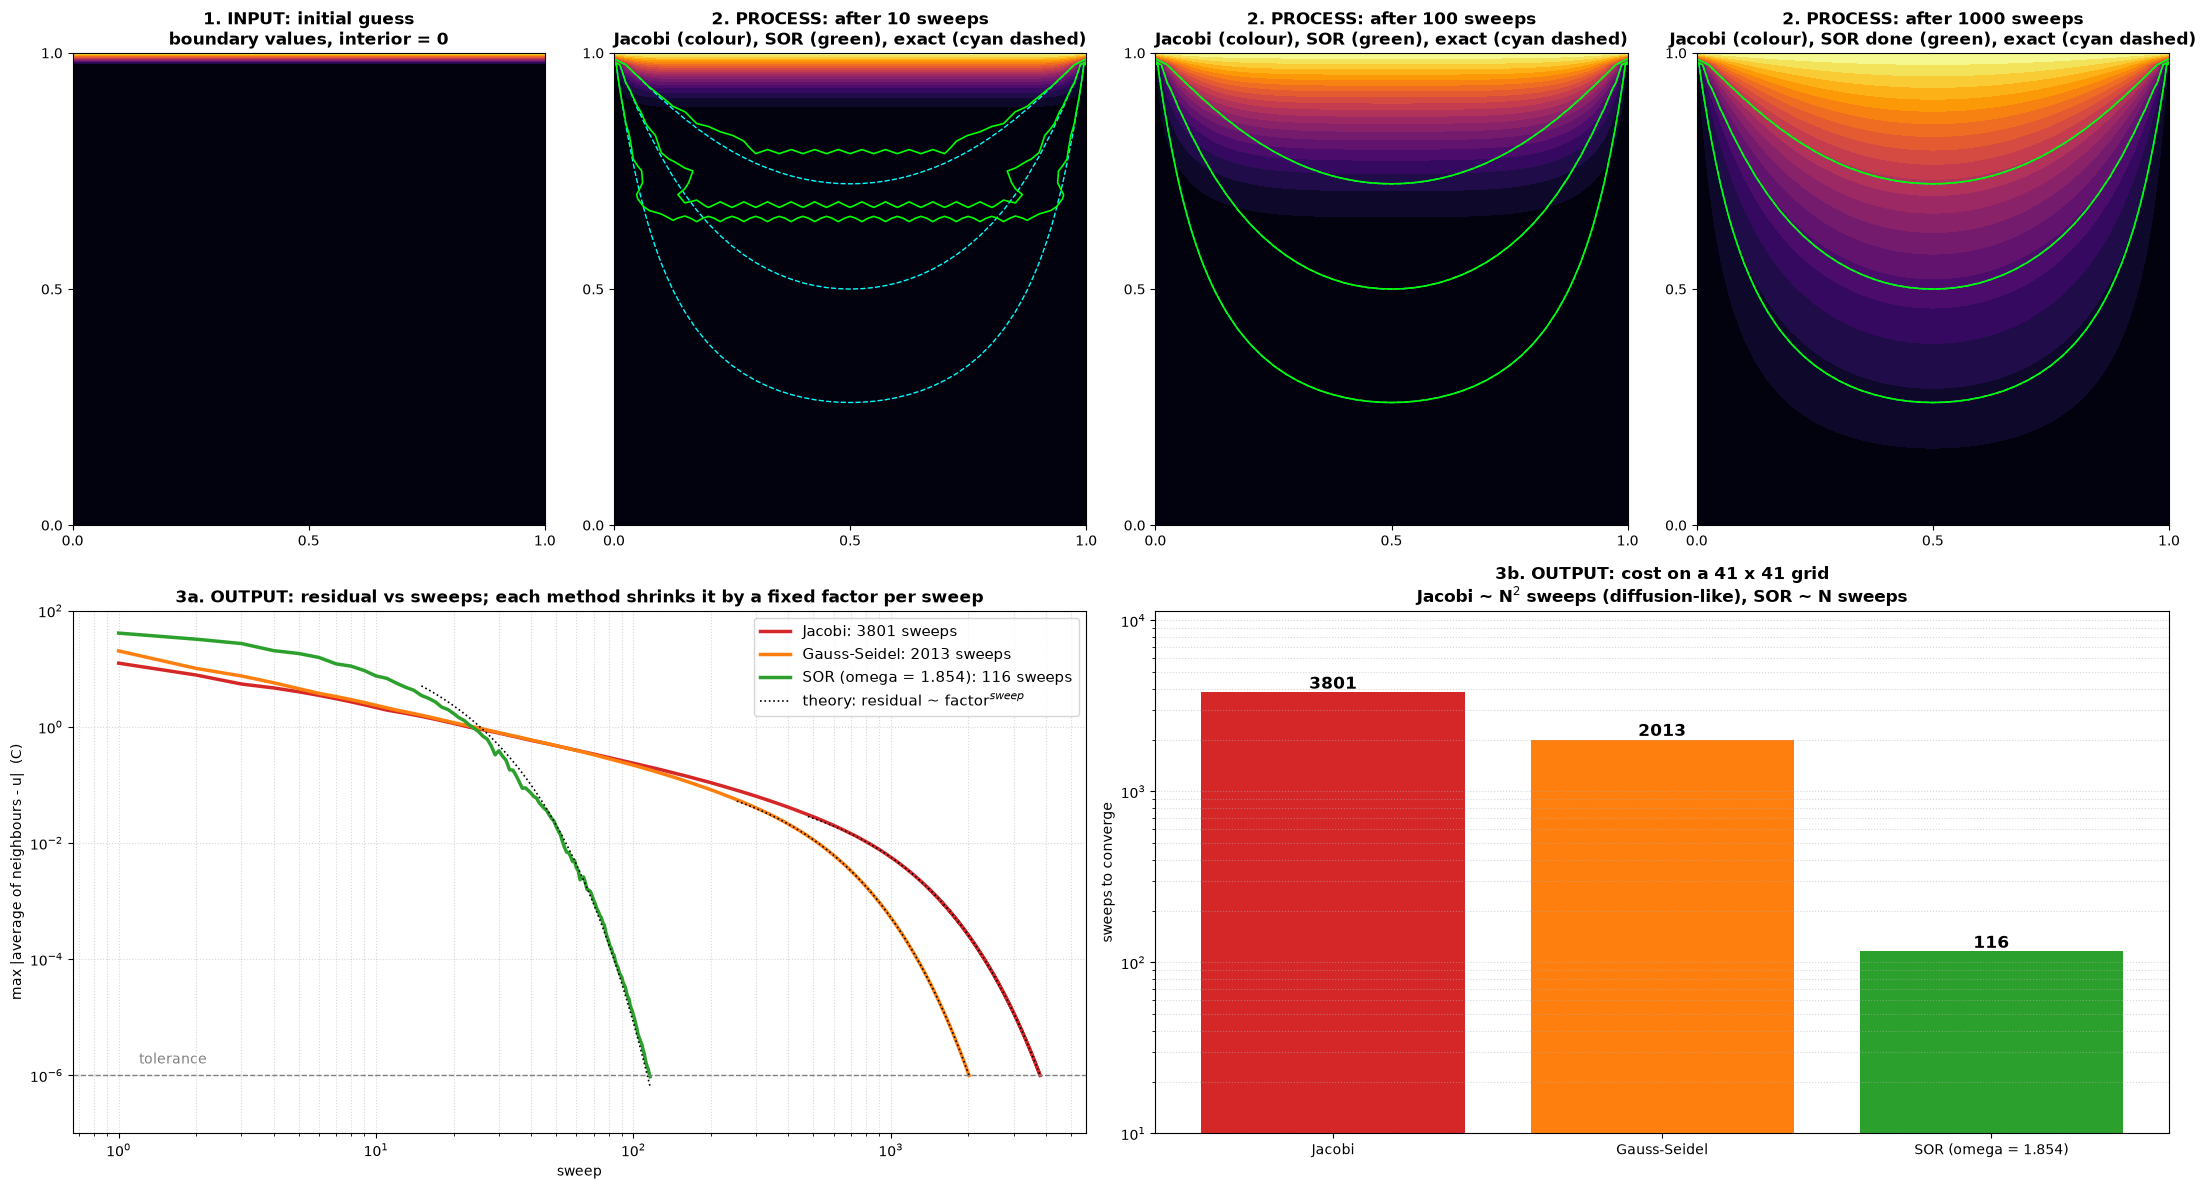

In [4]:
# ITERATIVE SOLVERS: INPUT -> PROCESS -> OUTPUT
import numpy as np
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(22, 12))
gs = fig.add_gridspec(2, 4)
X2, Y2 = np.meshgrid(x2, x2)
jac_snaps = runs['Jacobi'][2]
sor_name = f'SOR (omega = {omega_opt:.3f})'
sor_snaps = runs[sor_name][2]
levels = np.linspace(0, 100, 21)

# Row 1: INPUT (initial guess) and PROCESS (Jacobi vs SOR after the same number of sweeps)
ax = fig.add_subplot(gs[0, 0])
ax.contourf(X2, Y2, ub2, levels=levels, cmap='inferno')
ax.set_title('1. INPUT: initial guess\nboundary values, interior = 0', fontsize=12, fontweight='bold')
for col, it in enumerate(keep, start=1):
    ax = fig.add_subplot(gs[0, col])
    ax.contourf(X2, Y2, jac_snaps[it], levels=levels, cmap='inferno')
    ax.contour(X2, Y2, U_direct, levels=[10, 25, 50], colors='cyan', linewidths=1, linestyles='--')
    ax.contour(X2, Y2, sor_snaps[it], levels=[10, 25, 50], colors='lime', linewidths=1.2)
    sor_txt = 'SOR (green)' if it < len(runs[sor_name][1]) else 'SOR done (green)'
    ax.set_title(f'2. PROCESS: after {it} sweeps\nJacobi (colour), {sor_txt}, exact (cyan dashed)',
                 fontsize=12, fontweight='bold')
for ax in fig.axes:
    ax.set_aspect('equal')
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])

# Row 2: OUTPUT (convergence history and cost)
ax = fig.add_subplot(gs[1, :2])
colors = {'Jacobi': 'tab:red', 'Gauss-Seidel': 'tab:orange', sor_name: 'tab:green'}
for name, (_, res, _) in runs.items():
    it = np.arange(1, len(res) + 1)
    ax.semilogy(it, res, color=colors[name], lw=2.5, label=f'{name}: {len(res)} sweeps')
    a = len(res) // 2                                   # anchor the theory line half-way
    tail = it[a // 4:]
    ax.semilogy(tail, res[a] * rates[name]**(tail - it[a]), ':', color='k', lw=1.2)
ax.plot([], [], 'k:', lw=1.2, label='theory: residual ~ factor$^{sweep}$')
ax.axhline(1e-6, color='gray', ls='--', lw=1)
ax.text(1.2, 1.6e-6, 'tolerance', color='gray')
ax.set_xscale('log')
ax.set_ylim(1e-7, 100)
ax.set_xlabel('sweep')
ax.set_ylabel('max |average of neighbours - u|  (C)')
ax.grid(True, which='both', linestyle=':', alpha=0.5)
ax.legend(fontsize=11)
ax.set_title('3a. OUTPUT: residual vs sweeps; each method shrinks it by a fixed factor per sweep',
             fontsize=12, fontweight='bold')

ax = fig.add_subplot(gs[1, 2:])
names = list(runs)
n_sweeps = [len(runs[n][1]) for n in names]
bars = ax.bar(names, n_sweeps, color=[colors[n] for n in names])
for b_, n_ in zip(bars, n_sweeps):
    ax.text(b_.get_x() + b_.get_width() / 2, n_ * 1.05, f'{n_}', ha='center', fontsize=12, fontweight='bold')
ax.set_yscale('log')
ax.set_ylim(10, max(n_sweeps) * 3)
ax.set_ylabel('sweeps to converge')
ax.grid(True, axis='y', which='both', linestyle=':', alpha=0.5)
ax.set_title(f'3b. OUTPUT: cost on a {N2} x {N2} grid\nJacobi ~ N$^2$ sweeps (diffusion-like), SOR ~ N sweeps',
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## Part 3: Steady pressure around wells (Laplace and Poisson)

The same reservoir as Part 3 of `Diffusion_Equation.ipynb` ($k$ = 100 mD, $\mu$ = 1 mPa s, $\phi$ = 0.2, $c_t = 10^{-9}$ 1/Pa, $h$ = 10 m, $q$ = 0.005 m³/s), but now the outer boundary is held at constant pressure $p_e$ (for example by a strong aquifer). After a while the pressure stops changing: the transient (parabolic) problem becomes a steady (elliptic) one.

**3a. One well, radial (Laplace).** With $\partial_t p = 0$ the radial equation $\frac{1}{r}\frac{d}{dr}\left(r\frac{dp}{dr}\right) = 0$ gives the **Thiem** solution

$$p(r) = p_e - \frac{q\mu}{2\pi k h}\,\ln\frac{r_e}{r}$$

$\nabla^2 p = 0$ means $\nabla\cdot\mathbf v = 0$: no fluid is stored any more, so **the same rate $q$ flows through every circle** around the well.

**3b. A producer and an injector in a square reservoir (Poisson).** Wells are point sinks and sources, so

$$\nabla^2 p = \frac{\mu}{k h}\left[q\,\delta(\mathbf x - \mathbf x_{prod}) - q\,\delta(\mathbf x - \mathbf x_{inj})\right], \qquad p = p_e \text{ on the edges}$$

Two checks use ideas from the vector calculus notebooks:
- **Divergence theorem:** the inflow through any closed curve around the producer equals $q$, whatever its size, as long as it encloses only that well.
- **Mean-value property:** around a well, $p$ = (harmonic part) + $\frac{q\mu}{2\pi kh}\ln r$. Averaging over a circle removes the variation of the harmonic part, so the circle average grows exactly like $\frac{q\mu}{2\pi kh}\ln r$: the Thiem slope.

In [5]:
# STEADY PRESSURE: transient radial flow -> Thiem; 2D Poisson with a producer and an injector
import numpy as np
from scipy.linalg import solve_banded
from scipy.interpolate import RegularGridInterpolator

# 1. Reservoir, fluid and well properties (SI units)
mD = 9.869233e-16
k = 100 * mD
mu = 1.0e-3
phi = 0.20
ct = 1.0e-9
H = 10.0                           # layer thickness (m)
q = 0.005                          # well rate (m^3/s)
p_e = 30.0e6                       # pressure held at the outer boundary (Pa)
eta = k / (phi * mu * ct)
coef2 = q * mu / (2 * np.pi * k * H)          # Thiem slope per unit ln r
print(f"eta = {eta:.3f} m^2/s, Thiem slope q mu / (2 pi k h) = {coef2 / 1e6:.4f} MPa per unit ln r")

# --- 3a. Radial: implicit finite volumes with constant pressure at r_e ---
rw, re = 0.1, 500.0
Nr = 200
rf = np.geomspace(rw, re, Nr + 1)
rc = np.sqrt(rf[:-1] * rf[1:])
S = phi * ct * np.pi * H * (rf[1:]**2 - rf[:-1]**2)
T = 2 * np.pi * H * k / mu * rf[1:-1] / np.diff(rc)
T_out = 2 * np.pi * H * k / mu * re / (re - rc[-1])          # last ring -> boundary at p_e
T_left = np.concatenate([[0.0], T])
T_right = np.concatenate([T, [T_out]])
src = np.zeros(Nr)
src[0] = -q
bnd = np.zeros(Nr)
bnd[-1] = T_out * p_e

t_r = np.concatenate([[0.0], np.geomspace(1.0, 20 * 86400.0, 300)])
p = np.full(Nr, p_e)
Pr = np.empty((len(t_r), Nr))
Pr[0] = p
for n in range(1, len(t_r)):
    dt = t_r[n] - t_r[n - 1]
    ab = np.zeros((3, Nr))
    ab[0, 1:] = -T
    ab[1] = S / dt + T_left + T_right
    ab[2, :-1] = -T
    p = solve_banded((1, 1), ab, S / dt * p + src + bnd)
    Pr[n] = p
flow_r = T[None, :] * (Pr[:, 1:] - Pr[:, :-1])              # rate toward the well through each face


def thiem(r):
    return p_e - coef2 * np.log(re / r)


print(f"\n3a radial: after {t_r[-1] / 86400:.0f} days, max |p - Thiem| = {np.abs(Pr[-1] - thiem(rc)).max() / 1e6:.4f} MPa "
      f"(drawdown at the well {(p_e - Pr[-1, 0]) / 1e6:.3f} MPa)")
print(f"           flow through every face: min {flow_r[-1].min():.6f}, max {flow_r[-1].max():.6f} m^3/s (q = {q})")
t_steady = t_r[np.argmax(np.abs(Pr - thiem(rc)).max(axis=1) < 0.01e6)]
print(f"           within 0.01 MPa of Thiem after {t_steady / 3600:.1f} hours (r_e^2 / eta = {re**2 / eta / 3600:.1f} hours)")

# --- 3b. 2D Poisson: producer and injector in a square, p = p_e on the edges ---
Lsq = 1000.0
Np = 201
xs = np.linspace(0, Lsq, Np)
dxs = xs[1] - xs[0]
XS, YS = np.meshgrid(xs, xs)
i_prod, i_inj, j_w = 70, 130, 100                          # producer (350, 500), injector (650, 500)
s_well = q * mu / (k * H)                                   # Pa: strength of a point well
f = np.zeros((Np, Np))
f[j_w, i_prod] = +s_well / dxs**2                          # sink: pressure minimum
f[j_w, i_inj] = -s_well / dxs**2                           # source: pressure maximum
ubp = np.full((Np, Np), p_e)
ubp[1:-1, 1:-1] = 0.0
Pp = solve_poisson(ubp, f, dxs)


def box_inflow(P, i0, j0, w):
    # Darcy inflow (m^3/s) through the square of half-width w cells around cell (j0, i0)
    jl, jh, il, ih = j0 - w, j0 + w, i0 - w, i0 + w
    d = (np.sum(P[jl:jh + 1, il - 1] - P[jl:jh + 1, il]) + np.sum(P[jl:jh + 1, ih + 1] - P[jl:jh + 1, ih])
         + np.sum(P[jl - 1, il:ih + 1] - P[jl, il:ih + 1]) + np.sum(P[jh + 1, il:ih + 1] - P[jh, il:ih + 1]))
    return k * H / mu * d


half_widths = np.arange(2, 29, 2)
inflow_prod = np.array([box_inflow(Pp, i_prod, j_w, w) for w in half_widths])
inflow_inj = np.array([box_inflow(Pp, i_inj, j_w, w) for w in half_widths])
print(f"\n3b Poisson: inflow through squares around the producer: {inflow_prod.min():.6f} .. {inflow_prod.max():.6f} m^3/s (q = {q})")
print(f"            inflow through squares around the injector: {inflow_inj.min():.6f} .. {inflow_inj.max():.6f} m^3/s (-q)")
print(f"            net flow through the reservoir edges: {box_inflow(Pp, Np // 2, Np // 2, Np // 2 - 1):.1e} m^3/s")

# Mean-value property: circle averages around the producer grow like coef2 * ln r
interp_p = RegularGridInterpolator((xs, xs), Pp)
th = np.linspace(0, 2 * np.pi, 1440, endpoint=False)
r_circ = np.geomspace(20, 250, 15)
xp, yp = xs[i_prod], xs[j_w]
p_circ = np.array([interp_p(np.c_[yp + R * np.sin(th), xp + R * np.cos(th)]).mean() for R in r_circ])
slope_fit = np.polyfit(np.log(r_circ), p_circ, 1)[0]
print(f"            circle-average slope d<p>/d ln r = {slope_fit / 1e6:.4f} MPa vs Thiem {coef2 / 1e6:.4f} MPa "
      f"({100 * (slope_fit / coef2 - 1):+.2f} %)")

eta = 0.493 m^2/s, Thiem slope q mu / (2 pi k h) = 0.8063 MPa per unit ln r

3a radial: after 20 days, max |p - Thiem| = 0.0003 MPa (drawdown at the well 6.851 MPa)
           flow through every face: min 0.005000, max 0.005000 m^3/s (q = 0.005)
           within 0.01 MPa of Thiem after 119.2 hours (r_e^2 / eta = 140.7 hours)

3b Poisson: inflow through squares around the producer: 0.005000 .. 0.005000 m^3/s (q = 0.005)
            inflow through squares around the injector: -0.005000 .. -0.005000 m^3/s (-q)
            net flow through the reservoir edges: -4.0e-14 m^3/s
            circle-average slope d<p>/d ln r = 0.8063 MPa vs Thiem 0.8063 MPa (-0.01 %)


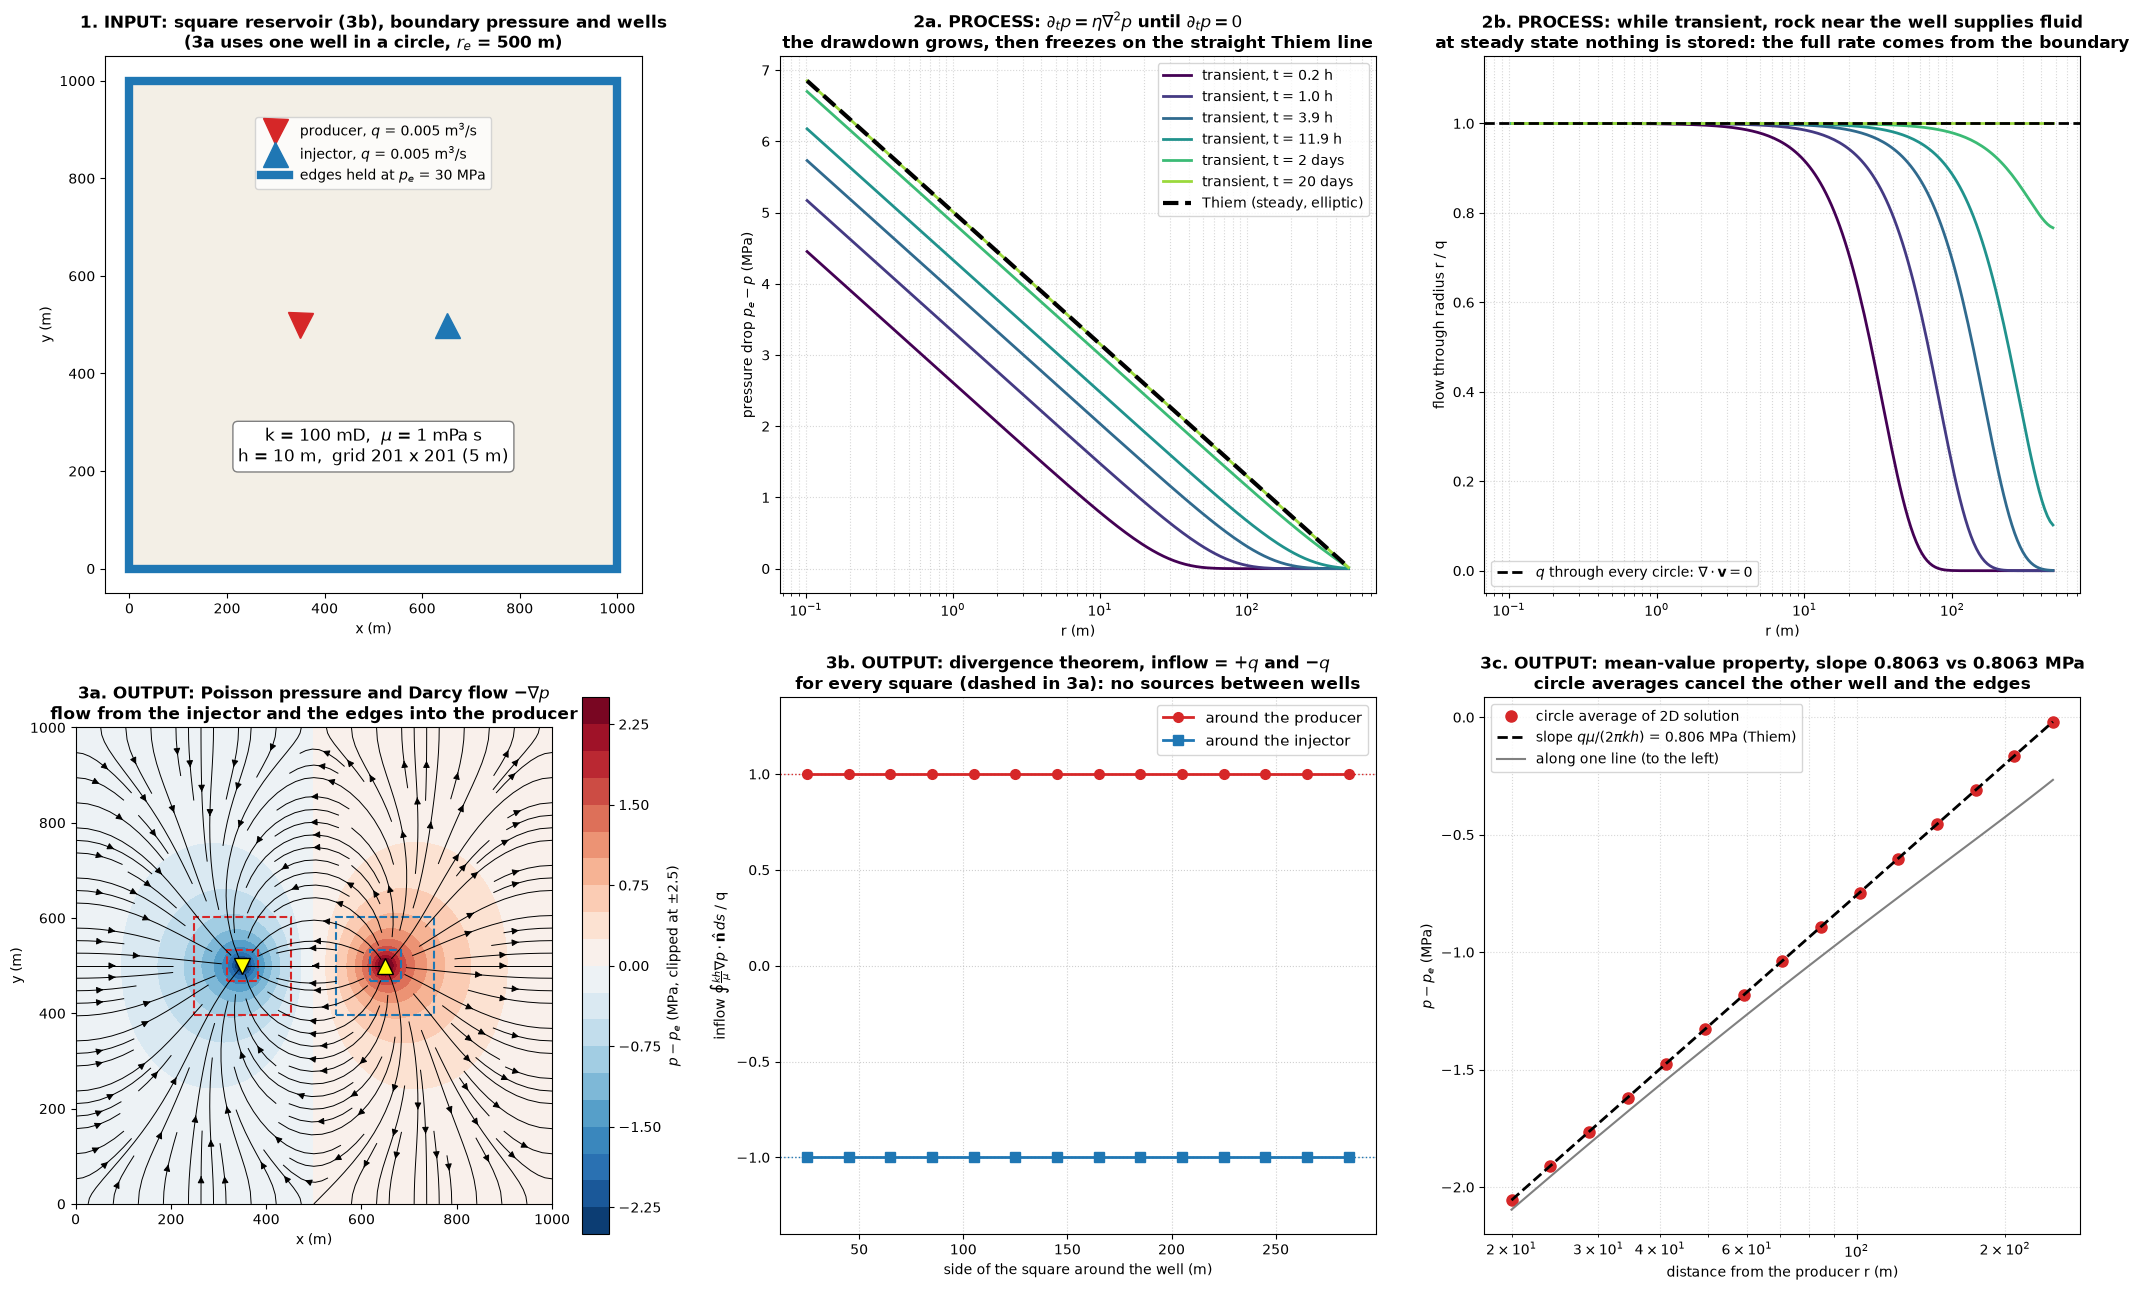

In [6]:
# STEADY PRESSURE: INPUT -> PROCESS -> OUTPUT
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(2, 3, figsize=(21, 13))
MPa = 1e6

# Panel 1: INPUT
ax = axes[0, 0]
ax.add_patch(Rectangle((0, 0), Lsq, Lsq, fc='#f3efe6', ec='tab:blue', lw=6))
ax.plot(xs[i_prod], xs[j_w], 'v', color='tab:red', ms=18, label=f'producer, $q$ = {q} m$^3$/s')
ax.plot(xs[i_inj], xs[j_w], '^', color='tab:blue', ms=18, label=f'injector, $q$ = {q} m$^3$/s')
ax.plot([], [], color='tab:blue', lw=6, label=f'edges held at $p_e$ = {p_e / MPa:.0f} MPa')
ax.text(Lsq / 2, 0.22 * Lsq, f'k = {k / mD:.0f} mD,  $\\mu$ = {mu * 1e3:.0f} mPa s\nh = {H:.0f} m,  grid {Np} x {Np} ({dxs:.0f} m)',
        ha='center', fontsize=12, bbox=dict(boxstyle='round', fc='white', ec='gray'))
ax.set_xlim(-50, Lsq + 50)
ax.set_ylim(-50, Lsq + 50)
ax.set_aspect('equal')
ax.legend(loc='upper center', fontsize=10, bbox_to_anchor=(0.5, 0.9))
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_title('1. INPUT: square reservoir (3b), boundary pressure and wells\n'
             f'(3a uses one well in a circle, $r_e$ = {re:.0f} m)', fontsize=12, fontweight='bold')

# Panel 2a: PROCESS (transient profiles settle onto Thiem)
ax = axes[0, 1]
t_show = np.array([600, 3600, 4 * 3600, 12 * 3600, 2 * 86400, 20 * 86400.0])
colors = plt.cm.viridis(np.linspace(0, 0.85, len(t_show)))
for ts, col in zip(t_show, colors):
    n = np.argmin(np.abs(t_r - ts))
    lab = f'{t_r[n] / 3600:.1f} h' if t_r[n] < 86400 else f'{t_r[n] / 86400:.0f} days'
    ax.semilogx(rc, (p_e - Pr[n]) / MPa, color=col, lw=2, label=f'transient, t = {lab}')
ax.semilogx(rc, (p_e - thiem(rc)) / MPa, 'k--', lw=3, label='Thiem (steady, elliptic)')
ax.set_xlabel('r (m)')
ax.set_ylabel('pressure drop $p_e - p$ (MPa)')
ax.grid(True, which='both', linestyle=':', alpha=0.5)
ax.legend(fontsize=10)
ax.set_title(r'2a. PROCESS: $\partial_t p = \eta\nabla^2 p$ until $\partial_t p = 0$' + '\n'
             'the drawdown grows, then freezes on the straight Thiem line', fontsize=12, fontweight='bold')

# Panel 2b: PROCESS (flow rate through each radius becomes q everywhere)
ax = axes[0, 2]
for ts, col in zip(t_show, colors):
    n = np.argmin(np.abs(t_r - ts))
    ax.semilogx(rf[1:-1], flow_r[n] / q, color=col, lw=2)
ax.axhline(1, color='k', ls='--', lw=2, label=r'$q$ through every circle: $\nabla\cdot\mathbf{v} = 0$')
ax.set_ylim(-0.05, 1.15)
ax.set_xlabel('r (m)')
ax.set_ylabel('flow through radius r / q')
ax.grid(True, which='both', linestyle=':', alpha=0.5)
ax.legend(fontsize=10, loc='lower left')
ax.set_title('2b. PROCESS: while transient, rock near the well supplies fluid\n'
             'at steady state nothing is stored: the full rate comes from the boundary', fontsize=12, fontweight='bold')

# Panel 3a: OUTPUT (2D Poisson pressure map and Darcy streamlines)
ax = axes[1, 0]
lim = 2.5
cf = ax.contourf(XS, YS, np.clip((Pp - p_e) / MPa, -lim, lim), levels=np.linspace(-lim, lim, 21), cmap='RdBu_r')
gpy, gpx = np.gradient(Pp, dxs)
ax.streamplot(xs, xs, -gpx, -gpy, color='k', density=1.3, linewidth=0.7, arrowsize=1.0)
ax.plot(xs[i_prod], xs[j_w], 'v', color='yellow', ms=12, mec='k')
ax.plot(xs[i_inj], xs[j_w], '^', color='yellow', ms=12, mec='k')
for w in (6, 20):
    for i0, col in ((i_prod, 'tab:red'), (i_inj, 'tab:blue')):
        ax.add_patch(Rectangle((xs[i0] - (w + 0.5) * dxs, xs[j_w] - (w + 0.5) * dxs), (2 * w + 1) * dxs, (2 * w + 1) * dxs,
                               fill=False, ec=col, lw=1.5, ls='--'))
fig.colorbar(cf, ax=ax, label=f'$p - p_e$ (MPa, clipped at $\\pm${lim})')
ax.set_aspect('equal')
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_title('3a. OUTPUT: Poisson pressure and Darcy flow $-\\nabla p$\n'
             'flow from the injector and the edges into the producer', fontsize=12, fontweight='bold')

# Panel 3b: OUTPUT (divergence theorem: inflow through squares)
ax = axes[1, 1]
size_m = (2 * half_widths + 1) * dxs
ax.plot(size_m, inflow_prod / q, 'o-', color='tab:red', lw=2, ms=7, label='around the producer')
ax.plot(size_m, inflow_inj / q, 's-', color='tab:blue', lw=2, ms=7, label='around the injector')
ax.axhline(1, color='tab:red', ls=':', lw=1)
ax.axhline(-1, color='tab:blue', ls=':', lw=1)
ax.set_ylim(-1.4, 1.4)
ax.set_xlabel('side of the square around the well (m)')
ax.set_ylabel(r'inflow $\oint \frac{kh}{\mu}\nabla p\cdot\hat{\mathbf{n}}\,ds$ / q')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=11)
ax.set_title('3b. OUTPUT: divergence theorem, inflow = $+q$ and $-q$\n'
             'for every square (dashed in 3a): no sources between wells', fontsize=12, fontweight='bold')

# Panel 3c: OUTPUT (mean-value property: circle averages follow the Thiem slope)
ax = axes[1, 2]
ax.semilogx(r_circ, (p_circ - p_e) / MPa, 'o', color='tab:red', ms=8, label='circle average of 2D solution')
ax.semilogx(r_circ, (p_circ[0] + coef2 * np.log(r_circ / r_circ[0]) - p_e) / MPa, 'k--', lw=2,
            label=f'slope $q\\mu/(2\\pi kh)$ = {coef2 / MPa:.3f} MPa (Thiem)')
j_line = Pp[j_w, :i_prod + 1][::-1]
r_line = xs[i_prod] - xs[:i_prod + 1][::-1]
ok = (r_line >= 20) & (r_line <= 250)
ax.semilogx(r_line[ok], (j_line[ok] - p_e) / MPa, '-', color='gray', lw=1.5, label='along one line (to the left)')
ax.set_xlabel('distance from the producer r (m)')
ax.set_ylabel('$p - p_e$ (MPa)')
ax.grid(True, which='both', linestyle=':', alpha=0.5)
ax.legend(fontsize=10)
ax.set_title(f'3c. OUTPUT: mean-value property, slope {slope_fit / MPa:.4f} vs {coef2 / MPa:.4f} MPa\n'
             'circle averages cancel the other well and the edges', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## Summary: the three types side by side

| | Elliptic (this notebook) | Parabolic (diffusion) | Hyperbolic (wave) |
|---|---|---|---|
| equation | $\nabla^2 u = f$ | $u_t = D\nabla^2 u$ | $u_{tt} = c^2\nabla^2 u$ |
| role of $\nabla^2 u$ | must vanish (or equal the source) | sets the rate of change | sets the acceleration |
| information travels | everywhere at once: each point feels the whole boundary | everywhere at once, but fades with distance | at finite speed $c$, along characteristics |
| typical behaviour | smooth, no interior max or min | smooths and decays toward the elliptic solution | keeps its shape, travels, reflects |
| data | boundary only | initial + boundary | initial $u$, $u_t$ + boundary |
| numerical method | solve one big system (direct or iterative) | march in time; explicit needs $r \le 1/4$ (2D) | march in time; explicit needs $C \le 1/\sqrt2$ (2D) |

The three are linked: the elliptic problem is the long-time limit of the parabolic one, and Jacobi iteration for the elliptic problem *is* a parabolic time-stepper.